# Drive-cycle and electrical energy analysis

The telemetry generator supplies time, current, voltage, vehicle speed, and throttle position. This notebook uses those signals to answer a few questions that would be useful after a test run:

1) How far did the vehicle travel, and how much electrical energy did it use?
2) How much energy was consumed per kilometre?
3) Where did acceleration and braking occur?
4) Were there any unusually high power draws worth inspecting?

The analysis is a function that also accepts a CSV loaded with pd.read_csv, provided it has the same column names. All units and event thresholds are explicit so they can be adjusted for actual vehicle telemetry.


## 1. Imports and analysis functions

Only NumPy, pandas, and Matplotlib are needed, in addition to the supplied DataCreator.py. The two small helpers below find uninterrupted event intervals and check the input before any calculations run.


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from DataCreator import generate_data


REQUIRED_COLUMNS = (
    "time (ms)", "current (A)", "voltage (V)",
    "speed (km/h)", "throttle (%)",
)


def _event_runs(mask):
    """Return (start, end) indices for each consecutive True interval."""
    edges = np.diff(np.r_[False, mask, False].astype(np.int8))
    return zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1))


def _validate_telemetry(df):
    missing = [name for name in REQUIRED_COLUMNS if name not in df.columns]
    if missing:
        raise ValueError(f"Missing telemetry columns: {', '.join(missing)}")
    if len(df) < 2:
        raise ValueError("At least two telemetry rows are required")

    signals = {}
    for name in REQUIRED_COLUMNS:
        try:
            values = pd.to_numeric(df[name], errors="raise").to_numpy(dtype=float)
        except (TypeError, ValueError) as exc:
            raise ValueError(f"Column {name!r} must contain numbers") from exc
        if not np.isfinite(values).all():
            raise ValueError(f"Column {name!r} contains missing or infinite values")
        signals[name] = values

    if not np.all(np.diff(signals["time (ms)"]) > 0):
        raise ValueError("Timestamps must be strictly increasing")
    if np.any(signals["voltage (V)"] < 0) or np.any(signals["speed (km/h)"] < 0):
        raise ValueError("Voltage and speed cannot be negative")
    throttle = signals["throttle (%)"]
    if np.any((throttle < 0) | (throttle > 100)):
        raise ValueError("Throttle must be between 0 and 100 percent")

    return signals


In [9]:
def analyze_vehicle_data(
    df,
    *,
    acceleration_threshold_mps2=0.8,
    min_event_duration_s=0.5,
    smoothing_ms=101,
    high_power_factor=2.0,
    idle_speed_kmh=1.0,
    max_plot_points=2000,
):
    """Summarize drive-cycle energy and find acceleration, braking and power bursts.

    The input is a DataFrame using the column names in REQUIRED_COLUMNS.
    Timestamps need not start at zero and may be unevenly spaced.

    Returns summary values, event tables, and sampled series for plotting.
    """
    if acceleration_threshold_mps2 <= 0 or min_event_duration_s < 0:
        raise ValueError("Acceleration threshold must be positive; duration cannot be negative")
    if smoothing_ms <= 0 or high_power_factor <= 1 or idle_speed_kmh < 0:
        raise ValueError("Invalid smoothing, high-power, or idle-speed setting")
    if max_plot_points < 2:
        raise ValueError("max_plot_points must be at least 2")

    signals = _validate_telemetry(df)
    time_ms = signals["time (ms)"]
    current_a = signals["current (A)"]
    voltage_v = signals["voltage (V)"]
    speed_kmh = signals["speed (km/h)"]
    throttle_pct = signals["throttle (%)"]

    elapsed_s = (time_ms - time_ms[0]) / 1000.0
    dt_h = np.diff(time_ms) / 3_600_000.0
    duration_s = float(elapsed_s[-1])

    # Trapezoidal integration uses the actual timestamp differences.
    power_w = voltage_v * current_a
    average_power_w = (power_w[:-1] + power_w[1:]) / 2.0
    interval_net_wh = average_power_w * dt_h
    drawn_power_w = np.maximum(power_w, 0.0)
    recovered_power_w = np.maximum(-power_w, 0.0)
    drawn_wh = float(np.sum((drawn_power_w[:-1] + drawn_power_w[1:]) / 2 * dt_h))
    recovered_wh = float(np.sum((recovered_power_w[:-1] + recovered_power_w[1:]) / 2 * dt_h))
    net_wh = float(np.sum(interval_net_wh))

    # km/h times hours gives kilometres.
    interval_distance_km = (speed_kmh[:-1] + speed_kmh[1:]) / 2 * dt_h
    distance_km = float(np.sum(interval_distance_km))
    midpoint_speed_kmh = (speed_kmh[:-1] + speed_kmh[1:]) / 2
    stopped = midpoint_speed_kmh < idle_speed_kmh
    idle_seconds = float(np.sum(np.diff(elapsed_s)[stopped]))
    idle_net_wh = float(np.sum(interval_net_wh[stopped]))

    summary = {
        "duration_s": duration_s,
        "distance_km": distance_km,
        "average_speed_kmh": distance_km / (duration_s / 3600),
        "maximum_speed_kmh": float(np.max(speed_kmh)),
        "energy_drawn_wh": drawn_wh,
        "energy_recovered_wh": recovered_wh,
        "net_energy_wh": net_wh,
        "net_energy_wh_per_km": net_wh / distance_km if distance_km > 0 else np.nan,
        "idle_time_s": idle_seconds,
        "idle_net_energy_wh": idle_net_wh,
    }

    # Smooth speed before differentiating. The sample window approximates
    # smoothing_ms for unevenly spaced data, using the median sample period.
    median_dt_ms = float(np.median(np.diff(time_ms)))
    window = max(1, int(round(smoothing_ms / median_dt_ms)))
    if window % 2 == 0:
        window += 1
    smoothed_speed_mps = (
        pd.Series(speed_kmh / 3.6)
        .rolling(window=window, center=True, min_periods=1)
        .mean()
        .to_numpy()
    )
    acceleration_mps2 = np.gradient(smoothed_speed_mps, elapsed_s)

    events = []
    for label, mask in (
        ("Acceleration", acceleration_mps2 >= acceleration_threshold_mps2),
        ("Braking", acceleration_mps2 <= -acceleration_threshold_mps2),
    ):
        for start, end in _event_runs(mask):
            stop_s = elapsed_s[min(end, len(elapsed_s) - 1)]
            event_duration_s = float(stop_s - elapsed_s[start])
            if event_duration_s >= min_event_duration_s:
                events.append({
                    "event": label,
                    "start_s": float(elapsed_s[start]),
                    "end_s": float(stop_s),
                    "duration_s": event_duration_s,
                    "peak_abs_accel_mps2": float(np.max(np.abs(acceleration_mps2[start:end]))),
                })
    events_df = pd.DataFrame(events, columns=[
        "event", "start_s", "end_s", "duration_s", "peak_abs_accel_mps2"
    ]).sort_values("start_s").reset_index(drop=True)

    # This flags possible bursts relative to the run's usual positive power.
    # It is a review threshold, not an electrical safety specification.
    positive_power_w = power_w[power_w > 0]
    burst_threshold_w = (
        float(high_power_factor * np.median(positive_power_w))
        if len(positive_power_w) else np.inf
    )
    bursts = []
    for start, end in _event_runs(power_w > burst_threshold_w):
        bursts.append({
            "start_s": float(elapsed_s[start]),
            "end_s": float(elapsed_s[min(end, len(elapsed_s) - 1)]),
            "peak_power_kw": float(np.max(power_w[start:end]) / 1000),
        })
    bursts_df = pd.DataFrame(bursts, columns=["start_s", "end_s", "peak_power_kw"])

    cumulative_net_wh = np.r_[0.0, np.cumsum(interval_net_wh)]

    def sample_rows(indices):
        return pd.DataFrame({
            "time_s": elapsed_s[indices],
            "speed_kmh": speed_kmh[indices],
            "throttle_pct": throttle_pct[indices],
            "power_kw": power_w[indices] / 1000,
            "cumulative_net_wh": cumulative_net_wh[indices],
            "acceleration_mps2": acceleration_mps2[indices],
        })

    overview_idx = np.unique(np.linspace(0, len(df) - 1, min(len(df), max_plot_points)).astype(int))
    detail_idx = np.flatnonzero(elapsed_s <= 35)
    detail_idx = detail_idx[np.unique(np.linspace(
        0, len(detail_idx) - 1, min(len(detail_idx), max_plot_points)
    ).astype(int))]
    startup_idx = np.flatnonzero(elapsed_s <= 0.060)

    return {
        "summary": summary,
        "events": events_df,
        "power_bursts": bursts_df,
        "burst_threshold_w": burst_threshold_w,
        "overview": sample_rows(overview_idx),
        "first_35_seconds": sample_rows(detail_idx),
        "first_60_ms": sample_rows(startup_idx),
    }


## Checks on a known dataset

These checks use simple signals where distance and energy can be calculated by hand. They also test a stationary vehicle, signed current, and invalid data. The assertions raise an error if the calculations stop matching those expectations.


In [10]:
def test_frame(*, current=2.0, speed=36.0):
    return pd.DataFrame({
        "time (ms)": [0, 1000, 2000],
        "current (A)": [current] * 3,
        "voltage (V)": [10.0] * 3,
        "speed (km/h)": [speed] * 3,
        "throttle (%)": [25.0] * 3,
    })


check = analyze_vehicle_data(test_frame())
s = check["summary"]
assert np.isclose(s["duration_s"], 2.0)
assert np.isclose(s["distance_km"], 0.02)
assert np.isclose(s["net_energy_wh"], 20 * 2 / 3600)
assert np.isclose(s["net_energy_wh_per_km"], (20 * 2 / 3600) / 0.02)
assert check["events"].empty
assert check["power_bursts"].empty

stationary = analyze_vehicle_data(test_frame(speed=0.0))["summary"]
assert np.isnan(stationary["net_energy_wh_per_km"])
assert np.isclose(stationary["idle_time_s"], 2.0)

regen = analyze_vehicle_data(test_frame(current=-2.0))["summary"]
assert np.isclose(regen["energy_drawn_wh"], 0)
assert np.isclose(regen["energy_recovered_wh"], 20 * 2 / 3600)
assert regen["net_energy_wh"] < 0

uneven = test_frame().assign(**{"time (ms)": [1000, 2000, 4000]})
uneven_summary = analyze_vehicle_data(uneven)["summary"]
assert np.isclose(uneven_summary["duration_s"], 3.0)
assert np.isclose(uneven_summary["distance_km"], 0.03)
assert np.isclose(uneven_summary["net_energy_wh"], 20 * 3 / 3600)

phases = pd.DataFrame({
    "time (ms)": np.arange(9) * 1000,
    "current (A)": [2.0] * 9,
    "voltage (V)": [10.0] * 9,
    "speed (km/h)": [0, 3.6, 7.2, 10.8, 14.4, 10.8, 7.2, 3.6, 0],
    "throttle (%)": [25.0] * 9,
})
phase_events = analyze_vehicle_data(phases)["events"]
assert set(phase_events["event"]) == {"Acceleration", "Braking"}

burst_test = test_frame().assign(**{"current (A)": [2.0, 10.0, 2.0]})
assert len(analyze_vehicle_data(burst_test)["power_bursts"]) == 1

for broken in (
    test_frame().drop(columns="voltage (V)"),
    test_frame().assign(**{"time (ms)": [0, 1000, 1000]}),
    test_frame().assign(**{"speed (km/h)": [36.0, np.nan, 36.0]}),
    test_frame().assign(**{"throttle (%)": [25.0, 120.0, 25.0]}),
):
    try:
        analyze_vehicle_data(broken)
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid telemetry should have raised ValueError")

print("checks passed: units, uneven timestamps, events, power bursts, regeneration, and validation.")


checks passed: units, uneven timestamps, events, power bursts, regeneration, and validation.


## Analyze the 20-minute simulated drive

generate_data(1_200_000) creates roughly 20 minutes of readings at 1 ms spacing. Processing happens on the full-resolution data. Only the arrays used for plotting are sampled down. The raw generator isn't modified.


In [11]:
data = generate_data(1_200_000)
report = analyze_vehicle_data(data)

display_names = {
    "duration_s": ("Duration", "s"),
    "distance_km": ("Distance travelled", "km"),
    "average_speed_kmh": ("Average speed", "km/h"),
    "maximum_speed_kmh": ("Maximum speed", "km/h"),
    "energy_drawn_wh": ("Electrical energy drawn", "Wh"),
    "energy_recovered_wh": ("Electrical energy recovered", "Wh"),
    "net_energy_wh": ("Net electrical energy", "Wh"),
    "net_energy_wh_per_km": ("Net energy per distance", "Wh/km"),
    "idle_time_s": ("Time below 1 km/h", "s"),
    "idle_net_energy_wh": ("Net energy below 1 km/h", "Wh"),
}
summary_table = pd.DataFrame([
    (label, f"{report['summary'][key]:,.3f}", unit)
    for key, (label, unit) in display_names.items()
], columns=["Metric", "Value", "Unit"])
print(summary_table.to_string(index=False))
print("\nDetected driving events:")
print(report["events"].round(3).to_string(index=False))
print(f"\nPower burst threshold: {report['burst_threshold_w'] / 1000:.3f} kW")
print("Candidate power bursts:")
print(report["power_bursts"].round(4).to_string(index=False))


                     Metric     Value  Unit
                   Duration 1,199.999     s
         Distance travelled    16.535    km
              Average speed    49.605  km/h
              Maximum speed    50.000  km/h
    Electrical energy drawn   492.020    Wh
Electrical energy recovered     0.000    Wh
      Net electrical energy   492.020    Wh
    Net energy per distance    29.756 Wh/km
          Time below 1 km/h     0.139     s
    Net energy below 1 km/h     0.077    Wh

Detected driving events:
       event  start_s  end_s  duration_s  peak_abs_accel_mps2
Acceleration    0.000  6.955       6.955                  2.0
     Braking   14.981 19.992       5.011                  2.5
Acceleration   20.032 28.329       8.297                  1.5

Power burst threshold: 2.952 kW
Candidate power bursts:
 start_s  end_s  peak_power_kw
   0.006  0.027         4.5014


## Plots

The overview plots show the entire run. A second view zooms into the first 35 seconds, where most driving events occur. Since the simulated high-current bursts happen in the first few milliseconds, they get a separate 60 ms view rather than disappearing in the 20-minute plot.


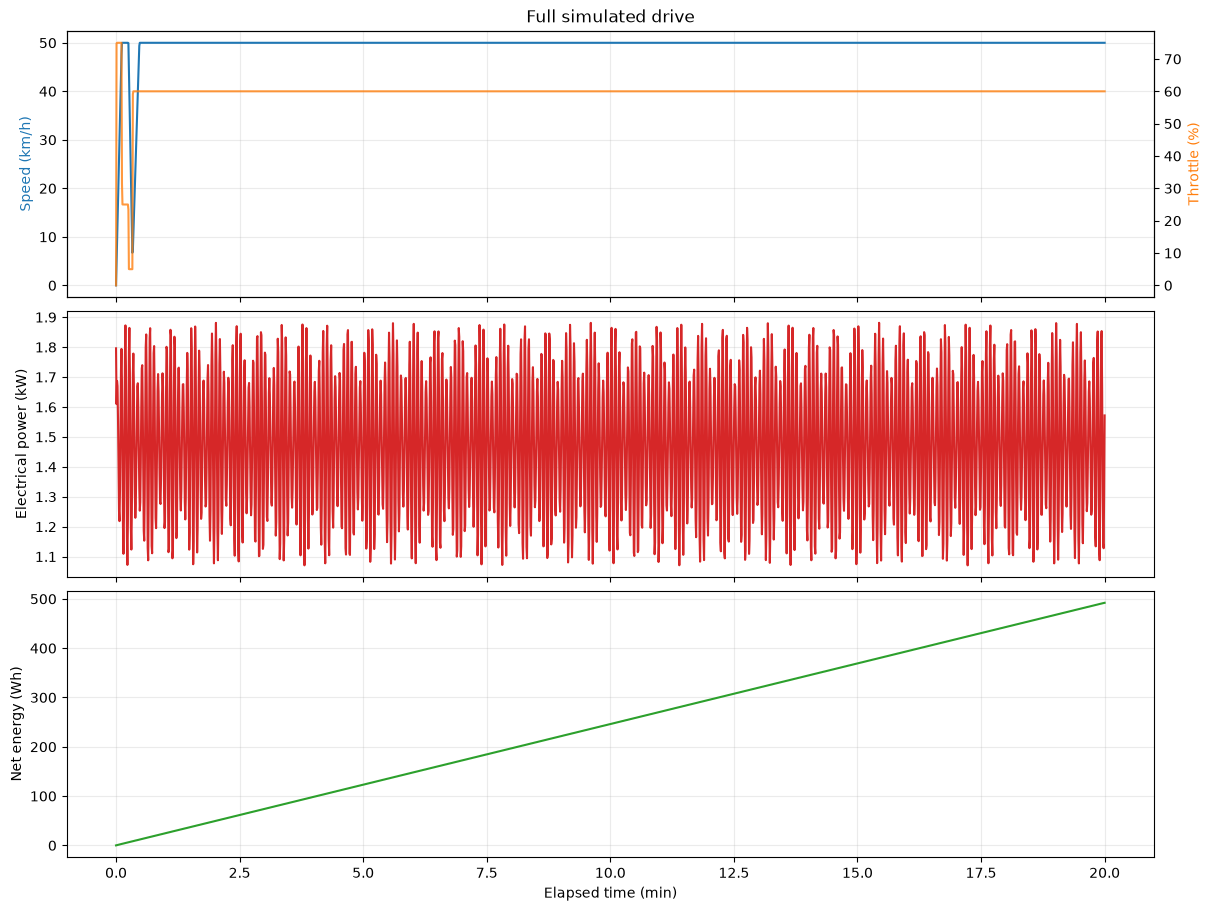

In [12]:
overview = report["overview"]
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, constrained_layout=True)

axes[0].plot(overview["time_s"] / 60, overview["speed_kmh"], color="tab:blue", label="Speed")
axes[0].set_ylabel("Speed (km/h)", color="tab:blue")
axes[0].grid(alpha=0.25)
throttle_axis = axes[0].twinx()
throttle_axis.plot(overview["time_s"] / 60, overview["throttle_pct"],
                   color="tab:orange", alpha=0.8, label="Throttle")
throttle_axis.set_ylabel("Throttle (%)", color="tab:orange")
axes[0].set_title("Full simulated drive")

axes[1].plot(overview["time_s"] / 60, overview["power_kw"], color="tab:red")
axes[1].set_ylabel("Electrical power (kW)")
axes[1].grid(alpha=0.25)

axes[2].plot(overview["time_s"] / 60, overview["cumulative_net_wh"], color="tab:green")
axes[2].set_ylabel("Net energy (Wh)")
axes[2].set_xlabel("Elapsed time (min)")
axes[2].grid(alpha=0.25)


Text(0.5, 1.0, 'Start of the drive: acceleration and braking phases')

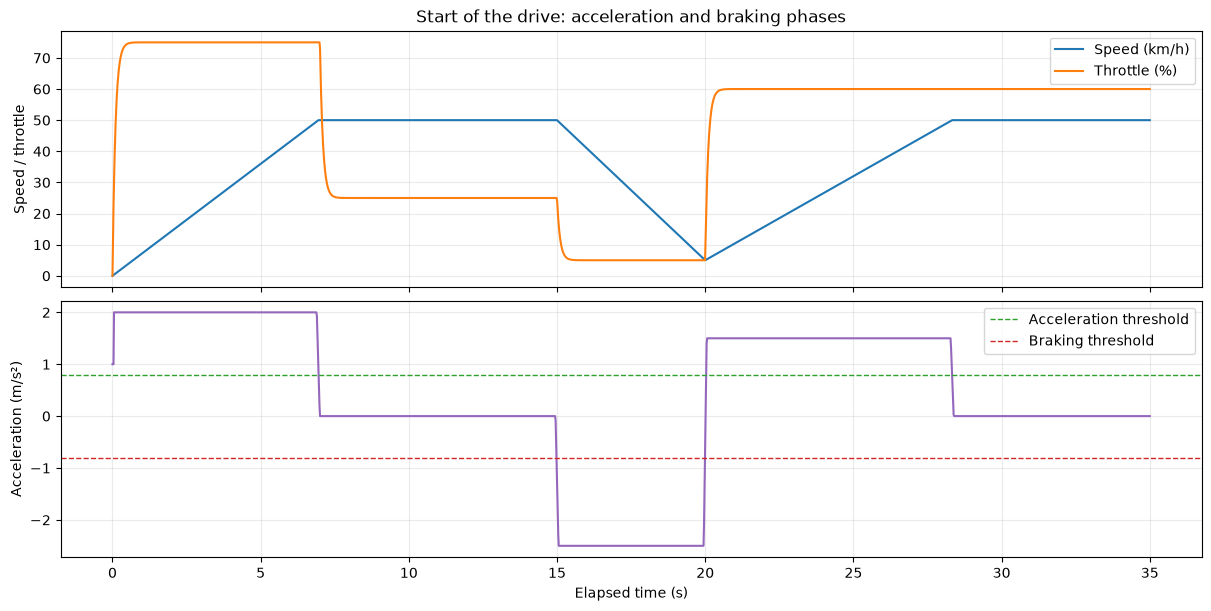

In [13]:
detail = report["first_35_seconds"]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True)

axes[0].plot(detail["time_s"], detail["speed_kmh"], label="Speed (km/h)", color="tab:blue")
axes[0].plot(detail["time_s"], detail["throttle_pct"], label="Throttle (%)", color="tab:orange")
axes[0].set_ylabel("Speed / throttle")
axes[0].legend(loc="best")
axes[0].grid(alpha=0.25)

axes[1].plot(detail["time_s"], detail["acceleration_mps2"], color="tab:purple")
axes[1].axhline(0.8, linestyle="--", color="tab:green", linewidth=1, label="Acceleration threshold")
axes[1].axhline(-0.8, linestyle="--", color="tab:red", linewidth=1, label="Braking threshold")
axes[1].set_ylabel("Acceleration (m/s²)")
axes[1].set_xlabel("Elapsed time (s)")
axes[1].legend(loc="best")
axes[1].grid(alpha=0.25)
axes[0].set_title("Start of the drive: acceleration and braking phases")


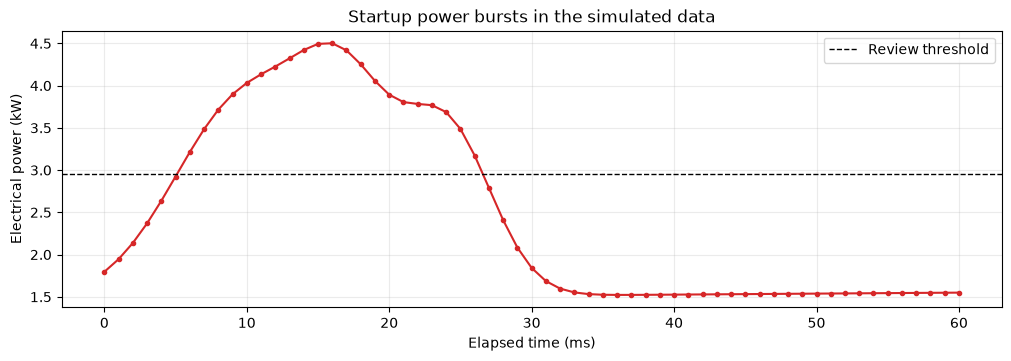

In [14]:
startup = report["first_60_ms"]
fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
ax.plot(startup["time_s"] * 1000, startup["power_kw"], marker=".", color="tab:red")
ax.axhline(report["burst_threshold_w"] / 1000, color="black", linestyle="--",
           linewidth=1, label="Review threshold")
ax.set(title="Startup power bursts in the simulated data", xlabel="Elapsed time (ms)",
       ylabel="Electrical power (kW)")
ax.legend()
ax.grid(alpha=0.25)


## Findings and limitations

1) Energy budget: Integrating voltage × current over time gives the net electrical energy for the run. Dividing by integrated distance gives Wh/km, a useful baseline for comparing routes or test configurations.
2) Driving phases: Differentiating smoothed speed identifies substantial acceleration and braking intervals. Smoothing removes very short fluctuations, while the minimum event duration rejects one-off sensor noise.
3) Power bursts: The relative threshold catches unusually high simulated power near startup. These are candidates for review - not confirmed faults - a real pack would need its own current, voltage and thermal limits.
4) Data limitations: The supplied current quickly settles near a constant value, and vehicle speed eventually reaches its imposed cap. This isn't a validated battery or drivetrain model. It also doesn't establish aerodynamic loss, mechanical efficiency, state of charge or true regenerative capability.
5) For actual CSV logs: Keep the same column names and units (or rename them after loading). Set thresholds based on the car and sensor noise. Check sensor calibration, sample dropouts and whether positive/negative current follow the assumed sign convention.

The main function returns plain dictionaries and DataFrames, so the same calculations can later be used by a backend endpoint or dashboard without rewriting the analysis.
